# tp1 machine learning

dataset tiny shakespeare. la tâche que j'ai choisie : retrouver quel personnage parle à partir de sa réplique. on garde les 8 persos qui parlent le plus, donc classif multiclasse avec un léger déséquilibre.

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.pipeline import make_pipeline, make_union
from sklearn.compose import ColumnTransformer
from sklearn.naive_bayes import ComplementNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

SEED = 42

In [2]:
raw = open("data/tinyshakespeare.txt", encoding="utf-8").read()
print(len(raw), "caractères")
print(raw[:400])

1115394 caractères
First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us kill him, and we'll have corn at our own price.
Is't a verdict?

All:
No more talking on't; let it 


In [3]:
# une réplique = un bloc séparé par une ligne vide, la 1ere ligne c'est "NOM:"
rows = []
for bloc in raw.strip().split("\n\n"):
    lignes = bloc.split("\n")
    if len(lignes) < 2 or not lignes[0].endswith(":"):
        continue
    rows.append({"speaker": lignes[0][:-1], "text": " ".join(lignes[1:])})

df_all = pd.DataFrame(rows)
print(df_all.shape, df_all.speaker.nunique(), "persos")
df_all.speaker.value_counts().head(15)

(7095, 2) 299 persos


speaker
GLOUCESTER          211
DUKE VINCENTIO      189
MENENIUS            161
ROMEO               160
PETRUCHIO           155
CORIOLANUS          148
KING RICHARD III    137
ISABELLA            127
JULIET              124
LEONTES             124
SICINIUS            117
KING EDWARD IV      109
QUEEN ELIZABETH     105
LUCIO               101
KING RICHARD II      98
Name: count, dtype: int64

In [4]:
N_PERSOS = 8
top = df_all.speaker.value_counts().head(N_PERSOS).index
df = df_all[df_all.speaker.isin(top)].reset_index(drop=True)
df.speaker.value_counts()

speaker
GLOUCESTER          211
DUKE VINCENTIO      189
MENENIUS            161
ROMEO               160
PETRUCHIO           155
CORIOLANUS          148
KING RICHARD III    137
ISABELLA            127
Name: count, dtype: int64

petite remarque : gloucester et king richard iii c'est le même personnage (richard est appelé gloucester avant d'être couronné). pareil menenius et coriolanus sont dans la même pièce. je m'attends à des confusions entre eux.

count    1288.000000
mean       29.191770
std        43.255099
min         1.000000
25%         7.000000
50%        15.000000
75%        34.000000
max       578.000000
Name: n_mots, dtype: float64


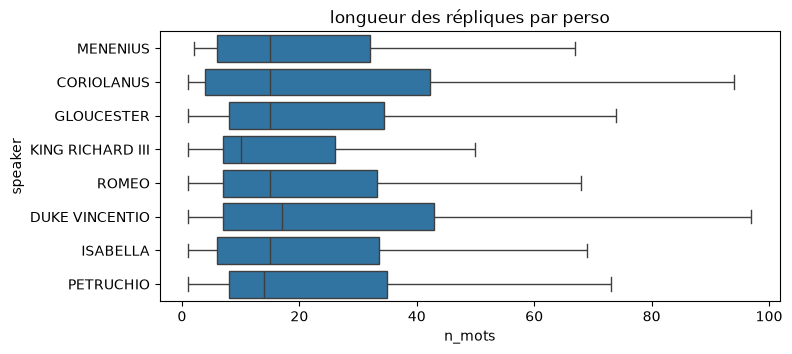

In [5]:
df["n_mots"] = df.text.str.split().str.len()
print(df.n_mots.describe())

plt.figure(figsize=(8, 3.5))
sns.boxplot(data=df, x="n_mots", y="speaker", showfliers=False)
plt.title("longueur des répliques par perso")
plt.show()

1) nettoyage et prétraitement

In [6]:
# doublons d'abord ("Away!", "I am content." etc), avant le split sinon fuite entre train et test
print("avant :", len(df))
df["text"] = df.text.str.strip()
df = df.drop_duplicates(subset="text").reset_index(drop=True)
print("après :", len(df))

avant : 1288
après : 1282


In [7]:
def nettoyer(t):
    t = t.lower()
    t = re.sub(r"[^a-z' ]", " ", t)  # je garde l'apostrophe pour 'tis, o'er, etc
    t = re.sub(r"\s+", " ", t).strip()
    return t

df["clean"] = df.text.apply(nettoyer)
# pour les n-grammes de caractères je garde la ponctuation, ça peut porter du style (! ? ;)
df["low"] = df.text.str.lower()

df[["speaker", "text", "clean"]].head(5)

,speaker,text,clean
0,MENENIUS,"What work's, my countrymen, in hand? where go ...",what work's my countrymen in hand where go you...
1,MENENIUS,"Why, masters, my good friends, mine honest nei...",why masters my good friends mine honest neighb...
2,MENENIUS,"I tell you, friends, most charitable care Have...",i tell you friends most charitable care have t...
3,MENENIUS,Either you must Confess yourselves wondrous ma...,either you must confess yourselves wondrous ma...
4,MENENIUS,There was a time when all the body's members R...,there was a time when all the body's members r...


je ne vire pas les stopwords : ici "thou", "thee", "my", "lord" etc c'est justement ce qui fait le style d'un perso. pas de stemming non plus, l'anglais de shakespeare passe assez mal dans les stemmers de toute façon.

In [8]:
# split stratifié 70 / 15 / 15
train_df, tmp = train_test_split(df, test_size=0.3, stratify=df.speaker, random_state=SEED)
val_df, test_df = train_test_split(tmp, test_size=0.5, stratify=tmp.speaker, random_state=SEED)
print(len(train_df), len(val_df), len(test_df))

# je sauvegarde pour réutiliser exactement le même split dans les tp2 et tp3
df["split"] = "train"
df.loc[val_df.index, "split"] = "val"
df.loc[test_df.index, "split"] = "test"
df.to_csv("data/speeches.csv", index=False)

897 192 193


2) représentation

In [9]:
# bag of words simple, fit sur le train uniquement
bow = CountVectorizer()
Xb = bow.fit_transform(train_df.clean)
print("bow :", Xb.shape, "| densité :", round(Xb.nnz / (Xb.shape[0] * Xb.shape[1]), 5))

tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
Xt = tfidf.fit_transform(train_df.clean)
print("tfidf mots 1-2 grammes :", Xt.shape)

idf = pd.Series(tfidf.idf_, index=tfidf.get_feature_names_out()).sort_values()
print("\nidf le plus bas (mots partout) :", list(idf.index[:12]))
print("idf le plus haut (mots rares) :", list(idf.index[-12:]))

bow : (897, 4155) | densité : 0.00551


tfidf mots 1-2 grammes : (897, 4245)

idf le plus bas (mots partout) : ['the', 'and', 'to', 'you', 'of', 'that', 'my', 'is', 'not', 'in', 'me', 'be']
idf le plus haut (mots rares) : ['myself no', 'blind', 'name and', 'names', 'nature never', 'nature of', 'naught', 'bless', 'nay but', 'nay good', 'nightingale', 'modesty']


In [10]:
tfidf_c = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=2, sublinear_tf=True)
Xc = tfidf_c.fit_transform(train_df.low)
print("tfidf chars 2-5 :", Xc.shape)

tfidf chars 2-5 : (897, 18680)


3) comparaison des modèles

on compare plusieurs représentations x plusieurs modèles, et on choisit sur la validation avec le f1 macro (l'accuracy seule est trompeuse vu que les classes sont pas équilibrées).

In [11]:
def repr_mots():
    return ColumnTransformer([("m", TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True), "clean")])

def repr_chars():
    return ColumnTransformer([("c", TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=2, sublinear_tf=True), "low")])

def repr_bow():
    return ColumnTransformer([("b", CountVectorizer(), "clean")])

def repr_mix():
    return ColumnTransformer([
        ("m", TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True), "clean"),
        ("c", TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=2, sublinear_tf=True), "low"),
    ])

reprs = {"bow": repr_bow, "tfidf mots": repr_mots, "tfidf chars": repr_chars, "mots+chars": repr_mix}
modeles = {
    "naive bayes": lambda: ComplementNB(),  # complement nb conseillé quand c'est déséquilibré
    "logreg": lambda: LogisticRegression(max_iter=3000, class_weight="balanced"),
    "svm lineaire": lambda: LinearSVC(class_weight="balanced"),
}

res = []
for rn, r in reprs.items():
    for mn, m in modeles.items():
        pipe = make_pipeline(r(), m())
        pipe.fit(train_df, train_df.speaker)
        pred = pipe.predict(val_df)
        res.append({
            "repr": rn, "modele": mn,
            "acc": accuracy_score(val_df.speaker, pred),
            "f1_macro": precision_recall_fscore_support(val_df.speaker, pred, average="macro", zero_division=0)[2],
        })

res = pd.DataFrame(res).sort_values("f1_macro", ascending=False)
res.round(3)

,repr,modele,acc,f1_macro
8,tfidf chars,svm lineaire,0.510,0.504
11,mots+chars,svm lineaire,0.490,0.474
10,mots+chars,logreg,0.484,0.474
7,tfidf chars,logreg,0.469,0.464
0,bow,naive bayes,0.474,0.455
4,tfidf mots,logreg,0.453,0.449
9,mots+chars,naive bayes,0.474,0.445
5,tfidf mots,svm lineaire,0.443,0.438
3,tfidf mots,naive bayes,0.453,0.436
6,tfidf chars,naive bayes,0.448,0.416


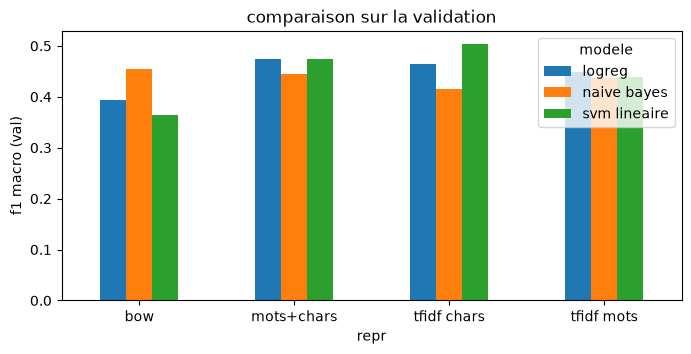

In [12]:
res.pivot(index="repr", columns="modele", values="f1_macro").round(3).plot.bar(figsize=(8, 3.5), rot=0)
plt.ylabel("f1 macro (val)")
plt.title("comparaison sur la validation")
plt.show()

In [13]:
# petit réglage de C (régularisation) pour logreg et svm, alpha pour nb, toujours sur la val
grille = {
    "logreg": [(C, lambda C=C: LogisticRegression(C=C, max_iter=3000, class_weight="balanced")) for C in [0.3, 1, 3, 10, 30, 100, 300]],
    "svm lineaire": [(C, lambda C=C: LinearSVC(C=C, class_weight="balanced")) for C in [0.03, 0.1, 0.3, 1, 3]],
    "naive bayes": [(a, lambda a=a: ComplementNB(alpha=a)) for a in [0.03, 0.1, 0.3, 1]],
}

reglage = []
for mn, essais in grille.items():
    for val, m in essais:
        for rn in ["tfidf mots", "tfidf chars", "mots+chars"]:
            pipe = make_pipeline(reprs[rn](), m())
            pipe.fit(train_df, train_df.speaker)
            pred = pipe.predict(val_df)
            f1 = precision_recall_fscore_support(val_df.speaker, pred, average="macro", zero_division=0)[2]
            reglage.append({"modele": mn, "repr": rn, "param": val, "f1_macro": f1})

reglage = pd.DataFrame(reglage)
best = reglage.loc[reglage.groupby("modele").f1_macro.idxmax()].sort_values("f1_macro", ascending=False)
best.round(3)

,modele,repr,param,f1_macro
31,svm lineaire,tfidf chars,1.0,0.504
13,logreg,tfidf chars,30.0,0.497
44,naive bayes,mots+chars,0.3,0.482


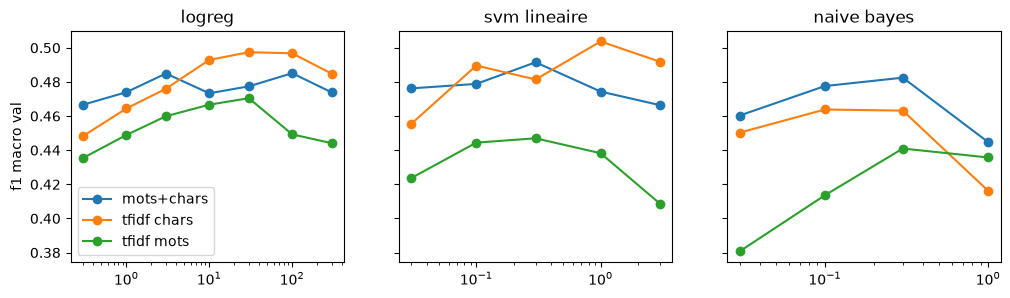

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3), sharey=True)
for ax, mn in zip(axes, grille):
    sub = reglage[reglage.modele == mn]
    for rn, g in sub.groupby("repr"):
        ax.plot(g.param, g.f1_macro, marker="o", label=rn)
    ax.set_xscale("log")
    ax.set_title(mn)
axes[0].set_ylabel("f1 macro val")
axes[0].legend()
plt.show()

4) évaluation

on réentraîne chaque modèle avec son meilleur réglage sur train+val, puis on passe le test une seule fois. j'ajoute un dummy (classe majoritaire) pour avoir un point de comparaison.

In [15]:
full_train = pd.concat([train_df, val_df])

def construire(mn, repr_nom, param):
    m = dict(grille[mn])[param]
    return make_pipeline(reprs[repr_nom](), m())

finaux = {row.modele: construire(row.modele, row.repr, row.param) for row in best.itertuples()}
finaux["dummy"] = make_pipeline(repr_mots(), DummyClassifier(strategy="most_frequent"))

lignes, preds = [], {}
for nom, pipe in finaux.items():
    pipe.fit(full_train, full_train.speaker)
    p = pipe.predict(test_df)
    preds[nom] = p
    pm, rm, fm, _ = precision_recall_fscore_support(test_df.speaker, p, average="macro", zero_division=0)
    lignes.append({"modele": nom, "accuracy": accuracy_score(test_df.speaker, p),
                   "precision_macro": pm, "rappel_macro": rm, "f1_macro": fm})

scores_test = pd.DataFrame(lignes).set_index("modele").sort_values("f1_macro", ascending=False)
scores_test.round(3)

,accuracy,precision_macro,rappel_macro,f1_macro
modele,,,,
svm lineaire,0.487,0.481,0.480,0.480
naive bayes,0.487,0.470,0.475,0.468
logreg,0.466,0.461,0.457,0.457
dummy,0.166,0.021,0.125,0.036


le dummy a quand même ~17% d'accuracy juste en disant gloucester tout le temps, mais f1 macro quasi nul. c'est l'exemple typique du cours.

In [16]:
meilleur = scores_test.index[0]
print("meilleur modèle :", meilleur)
print(classification_report(test_df.speaker, preds[meilleur], zero_division=0))

meilleur modèle : svm lineaire
                  precision    recall  f1-score   support

      CORIOLANUS       0.43      0.45      0.44        22
  DUKE VINCENTIO       0.55      0.59      0.57        29
      GLOUCESTER       0.50      0.50      0.50        32
        ISABELLA       0.40      0.42      0.41        19
KING RICHARD III       0.39      0.35      0.37        20
        MENENIUS       0.43      0.42      0.43        24
       PETRUCHIO       0.68      0.65      0.67        23
           ROMEO       0.46      0.46      0.46        24

        accuracy                           0.49       193
       macro avg       0.48      0.48      0.48       193
    weighted avg       0.49      0.49      0.49       193



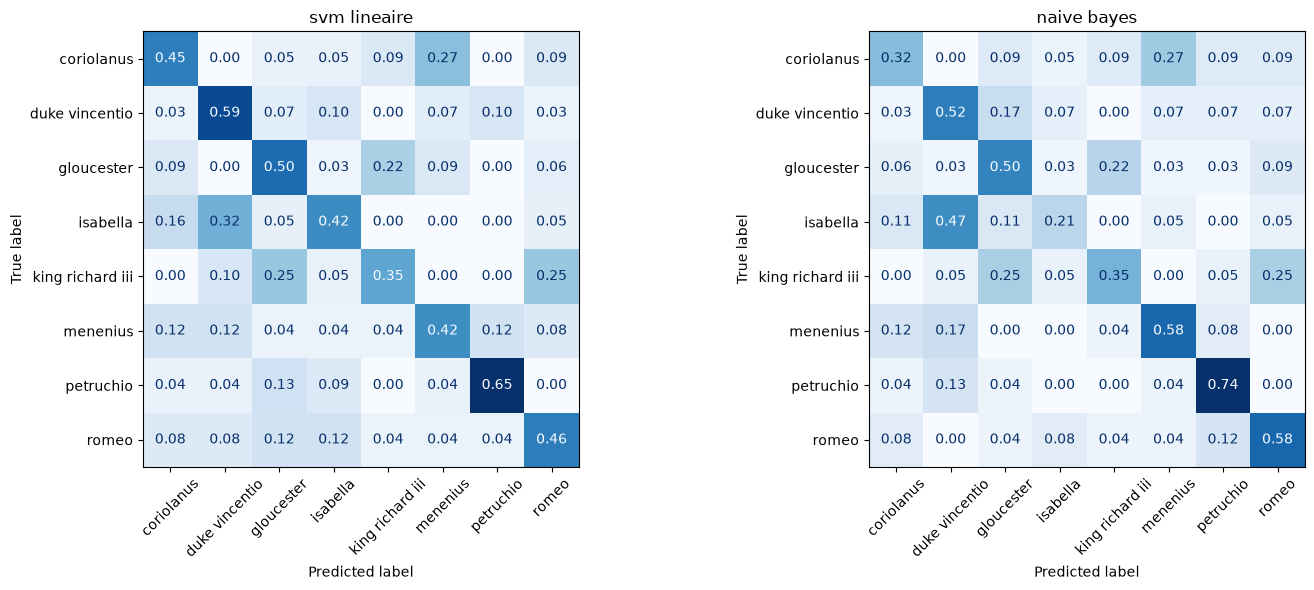

In [17]:
labels = sorted(top)
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, nom in zip(axes, [meilleur, scores_test.index[1]]):
    cm = confusion_matrix(test_df.speaker, preds[nom], labels=labels, normalize="true")
    ConfusionMatrixDisplay(cm, display_labels=[l.lower() for l in labels]).plot(
        ax=ax, cmap="Blues", values_format=".2f", colorbar=False, xticks_rotation=45)
    ax.set_title(nom)
plt.tight_layout()
plt.show()

In [18]:
# quels mots poussent vers chaque perso ? on refait une logreg sur les mots seuls, plus lisible
lr_mots = make_pipeline(repr_mots(), LogisticRegression(C=10, max_iter=3000, class_weight="balanced"))
lr_mots.fit(full_train, full_train.speaker)
vocab = lr_mots[0].get_feature_names_out()
coefs = lr_mots[-1].coef_
for i, c in enumerate(lr_mots[-1].classes_):
    idx = np.argsort(coefs[i])[::-1][:10]
    print(f"{c.lower():18s}", ", ".join(v.split("__")[1] for v in vocab[idx]))

coriolanus         them, voices, gods, traitor, marcius, aufidius, so am, tush, ha, you
duke vincentio     provost, angelo, claudio, isabel, maid, escalus, him, he, the duke, this
gloucester         cousin, clarence, edward, lord, king, god, margaret, brother, upon what, the king
isabella           my brother, brother, alas, heaven, your honour, but, my lord, your will, calls, good father
king richard iii   richmond, madam, tyrrel, ratcliff, daughter, norfolk, catesby, you speak, king, high
menenius           tribunes, noble, general, sir sir, rome, well no, fellow, he, promise, be calm
petruchio          kate, hortensio, it, come, why, proceed, what, sirrah, thee, there the
romeo              love, what shall, dear, for, goose, whither, thou, out, courteous, thee


In [19]:
# quelques erreurs du meilleur modèle
err = test_df.assign(pred=preds[meilleur])
err = err[err.pred != err.speaker]
pd.set_option("display.max_colwidth", 120)
err[["speaker", "pred", "text"]].sample(8, random_state=1)

,speaker,pred,text
1268,PETRUCHIO,GLOUCESTER,I hope better.
402,GLOUCESTER,KING RICHARD III,"Madam, have comfort: all of us have cause To wail the dimming of our shining star; But none can cure their harms by ..."
195,CORIOLANUS,KING RICHARD III,"Say, then: 'tis true, I ought so."
63,MENENIUS,CORIOLANUS,Worthy man!
791,GLOUCESTER,CORIOLANUS,"The gates are open, let us enter too."
702,ROMEO,MENENIUS,I will follow you.
566,KING RICHARD III,GLOUCESTER,"Unless for that he comes to be your liege, You cannot guess wherefore the Welshman comes. Thou wilt revolt, and fly ..."
594,KING RICHARD III,GLOUCESTER,He said the truth: and what said Surrey then?


In [20]:
# est-ce que ça dépend de la longueur de la réplique ? (je pense que oui)
t = test_df.assign(ok=preds[meilleur] == test_df.speaker)
t.groupby(pd.cut(t.n_mots, [0, 5, 15, 40, 1000]), observed=True).ok.agg(["mean", "count"]).round(2)

,mean,count
n_mots,,
"(0, 5]",0.32,40
"(5, 15]",0.42,59
"(15, 40]",0.62,48
"(40, 1000]",0.57,46


bilan : les trois modèles sont très proches sur le test (f1 macro autour de 0.46-0.48), et avec 193 répliques de test 1 ou 2 points d'écart c'est du bruit, donc pas la peine de sur-interpréter le classement. ce qui joue le plus c'est la représentation, les n-grammes de caractères font mieux que les mots seuls (ils attrapent thou, hath, 'tis, la ponctuation...).

côté erreurs c'est assez logique : petruchio est le plus facile (kate, hortensio), et les persos d'une même pièce se mélangent : gloucester / king richard iii (même personne), isabella / duke vincentio (measure for measure), coriolanus / menenius. les répliques de moins de 5 mots sont quasi impossibles, ce qui est normal, même un humain ne saurait pas qui dit "is this done?".